In [1]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Running on CPU.")

Using device: cuda
GPU: Tesla T4


In [2]:
!pip install "torchmetrics[image,multimodal]" torch-fidelity scikit-image -q

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os, glob, zipfile, shutil
zips = glob.glob("/content/drive/MyDrive/*.zip")
print("Zip files found:", zips)

Mounted at /content/drive
Zip files found: ['/content/drive/MyDrive/cognitive_mirror-20261124T053716Z-1-001.zip']


In [5]:
D = "/content/drive/MyDrive/cognitive_mirror"
os.makedirs(D, exist_ok=True)

for z in zips:
    if "cognitive" in os.path.basename(z).lower():
        with zipfile.ZipFile(z) as zf:
            zf.extractall(D)

nested = os.path.join(D, "cognitive_mirror")
if os.path.isdir(nested):
    for n in os.listdir(nested):
        src_path = os.path.join(nested, n)
        dst_path = os.path.join(D, n)
        if os.path.exists(dst_path):
            if os.path.isdir(dst_path):
                shutil.rmtree(dst_path)
            else:
                os.remove(dst_path)
        shutil.move(src_path, D)
    os.rmdir(nested)

print(sorted(os.listdir(D)))

['ae_model.pt', 'data.npz', 'metrics.json', 'tokenizer_saved', 'transformer_model.pt', 'transformer_model_backup.pt', 'vae_model.pt']


In [6]:
import os, json, math, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import matplotlib.pyplot as plt
import pandas as pd
from torch.utils.data import DataLoader
from skimage.metrics import structural_similarity as ssim
from google.colab import drive

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42); np.random.seed(42)
drive.mount('/content/drive')
D = "/content/drive/MyDrive/cognitive_mirror"

d = np.load(f"{D}/data.npz")
X_train_img = torch.tensor(d["train"]).to(device)
X_val_img = torch.tensor(d["val"]).to(device)
img_labels = np.concatenate([d["smile_train"], d["smile_val"]])
split = len(X_train_img)
metrics = json.load(open(f"{D}/metrics.json"))
mse = nn.MSELoss()
orig_np = X_val_img.cpu().numpy()
print(device, X_train_img.shape, X_val_img.shape)
print("metrics keys:", list(metrics.keys()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuda torch.Size([18000, 2304]) torch.Size([2000, 2304])
metrics keys: ['accuracy', 'f1', 'precision', 'recall', 'threshold', 'label_names', 'ae_mse', 'ae_psnr', 'ae_ssim', 'vae_mse', 'vae_psnr', 'vae_ssim', 'vae_kl', 'lat_ae']


In [7]:
#Load VAE and AE
LAT_AE = metrics.get("lat_ae", 256)

class ImageAE(nn.Module):
    def __init__(self, latent=LAT_AE):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Unflatten(1, (1, 48, 48)),
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Flatten(), nn.Linear(256 * 3 * 3, latent))
        self.decoder = nn.Sequential(
            nn.Linear(latent, 256 * 3 * 3), nn.ReLU(), nn.Unflatten(1, (256, 3, 3)),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid(), nn.Flatten())
    def forward(self, x):
        return self.decoder(self.encoder(x))

class ImageVAE(nn.Module):
    def __init__(self, latent=32):
        super().__init__()
        self.hidden = nn.Sequential(
            nn.Unflatten(1, (1, 48, 48)),
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Flatten())
        self.mean_layer = nn.Linear(256 * 3 * 3, latent)
        self.logvar_layer = nn.Linear(256 * 3 * 3, latent)
        self.decoder = nn.Sequential(
            nn.Linear(latent, 256 * 3 * 3), nn.ReLU(), nn.Unflatten(1, (256, 3, 3)),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid(), nn.Flatten())
    def forward(self, x):
        h = self.hidden(x)
        mean = self.mean_layer(h); logvar = self.logvar_layer(h)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)
        return self.decoder(z), mean, logvar

img_ae = ImageAE().to(device)
img_ae.load_state_dict(torch.load(f"{D}/ae_model.pt", map_location=device)); img_ae.eval()
img_vae = ImageVAE().to(device)
img_vae.load_state_dict(torch.load(f"{D}/vae_model.pt", map_location=device)); img_vae.eval()
print("AE and VAE loaded.")

AE and VAE loaded.


In [8]:
#Build,train and save(GAN)
latent_dim = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, 3, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Tanh())
    def forward(self, z):
        return self.net(z.view(z.size(0), latent_dim, 1, 1))

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2, True),
            nn.Conv2d(32, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),
            nn.Flatten(), nn.Linear(256 * 3 * 3, 1))
    def forward(self, x):
        return self.net(x)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

generator = Generator().to(device); discriminator = Discriminator().to(device)
generator.apply(init_weights); discriminator.apply(init_weights)
gan_bce = nn.BCEWithLogitsLoss()
g_opt = optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
d_opt = optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))
gan_loader = DataLoader(X_train_img, batch_size=128, shuffle=True, drop_last=True)

def generate_faces(n):
    generator.eval()
    with torch.no_grad():
        out = generator(torch.randn(n, latent_dim, device=device))
    return ((out + 1) / 2).view(n, -1)

GAN_EPOCHS = 80          # raise to 150 for a final, sharper run
fixed_noise = torch.randn(8, latent_dim, device=device)
snapshot_epochs = [1, 10, 30, 60, GAN_EPOCHS]
snapshots = {}
d_losses, g_losses, d_real_scores, d_fake_scores = [], [], [], []

for epoch in range(1, GAN_EPOCHS + 1):
    generator.train(); discriminator.train()
    d_tot, g_tot, dr_tot, df_tot = 0, 0, 0, 0
    for real in gan_loader:
        b = real.size(0)
        real = real.view(b, 1, 48, 48) * 2 - 1
        fake = generator(torch.randn(b, latent_dim, device=device))
        d_real = discriminator(real); d_fake = discriminator(fake.detach())
        d_loss = gan_bce(d_real, torch.full_like(d_real, 0.9)) + gan_bce(d_fake, torch.zeros_like(d_fake))
        d_opt.zero_grad(); d_loss.backward(); d_opt.step()
        g_out = discriminator(fake)
        g_loss = gan_bce(g_out, torch.ones_like(g_out))
        g_opt.zero_grad(); g_loss.backward(); g_opt.step()
        d_tot += d_loss.item(); g_tot += g_loss.item()
        dr_tot += torch.sigmoid(d_real).mean().item(); df_tot += torch.sigmoid(d_fake).mean().item()
    nb = len(gan_loader)
    d_losses.append(d_tot / nb); g_losses.append(g_tot / nb)
    d_real_scores.append(dr_tot / nb); d_fake_scores.append(df_tot / nb)
    if epoch in snapshot_epochs:
        generator.eval()
        with torch.no_grad():
            snapshots[epoch] = ((generator(fixed_noise) + 1) / 2).cpu().numpy().reshape(-1, 48, 48)
    if epoch % 10 == 0 or epoch == 1:
        print("Epoch", epoch, "D:", round(d_losses[-1], 4), "G:", round(g_losses[-1], 4),
              "D(real):", round(d_real_scores[-1], 3), "D(fake):", round(d_fake_scores[-1], 3))

torch.save(generator.state_dict(), f"{D}/gan_generator.pt")
torch.save(discriminator.state_dict(), f"{D}/gan_discriminator.pt")
print("GAN saved.")

Epoch 1 D: 0.6715 G: 3.7261 D(real): 0.747 D(fake): 0.143
Epoch 10 D: 0.8482 G: 2.9437 D(real): 0.673 D(fake): 0.224
Epoch 20 D: 0.8166 G: 2.8781 D(real): 0.686 D(fake): 0.213
Epoch 30 D: 0.8645 G: 2.5047 D(real): 0.672 D(fake): 0.227
Epoch 40 D: 0.8193 G: 2.413 D(real): 0.679 D(fake): 0.221
Epoch 50 D: 0.7656 G: 2.4453 D(real): 0.695 D(fake): 0.202
Epoch 60 D: 0.7132 G: 2.5928 D(real): 0.718 D(fake): 0.182
Epoch 70 D: 0.6573 G: 2.8445 D(real): 0.744 D(fake): 0.154
Epoch 80 D: 0.6994 G: 3.0503 D(real): 0.745 D(fake): 0.154
GAN saved.


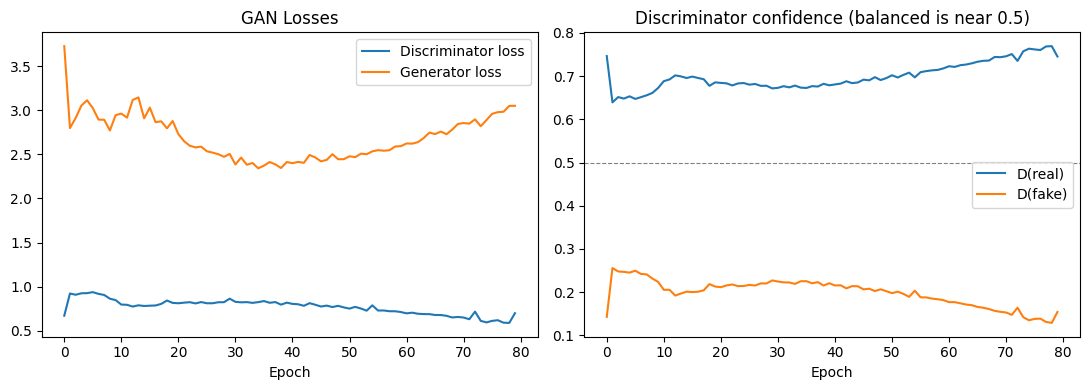

In [9]:
#GAN charts
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(d_losses, label="Discriminator loss"); plt.plot(g_losses, label="Generator loss")
plt.title("GAN Losses"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(d_real_scores, label="D(real)"); plt.plot(d_fake_scores, label="D(fake)")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
plt.title("Discriminator confidence (balanced is near 0.5)"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout(); plt.show()


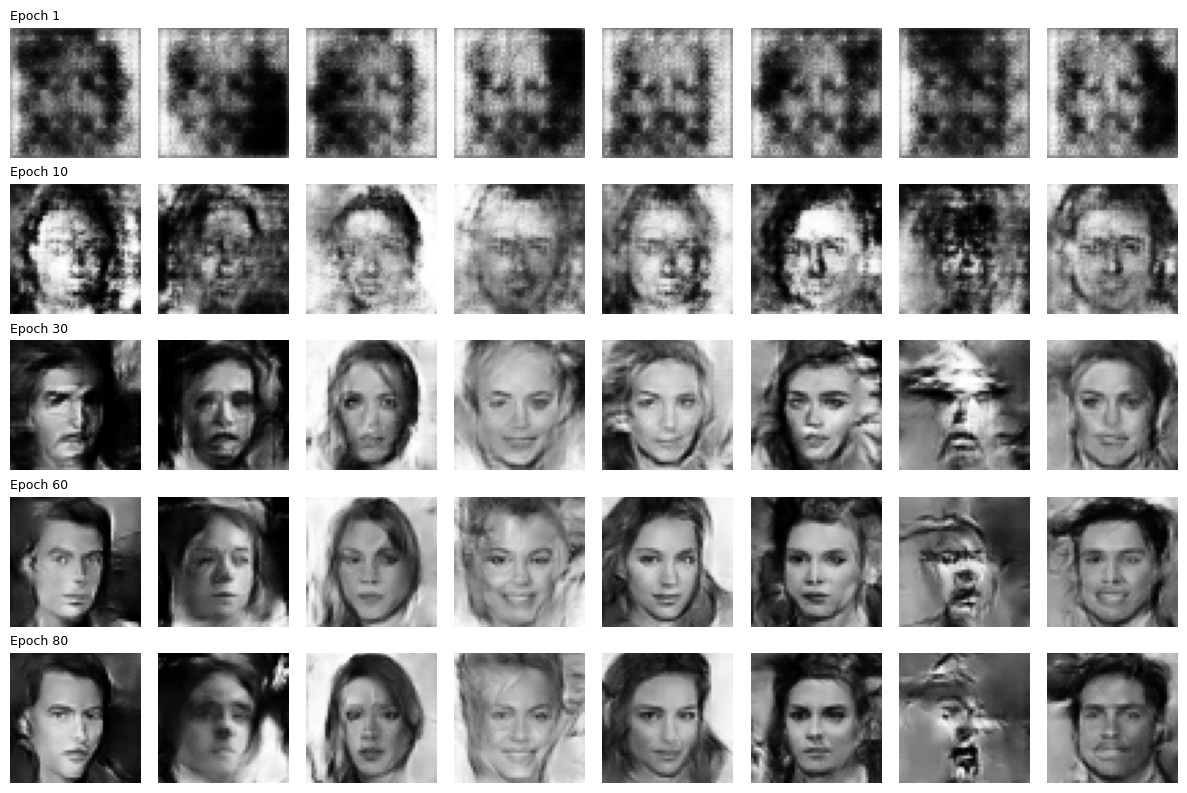

In [10]:
fig, axes = plt.subplots(len(snapshots), 8, figsize=(12, 1.6 * len(snapshots)))
for r, ep in enumerate(sorted(snapshots)):
    for c in range(8):
        axes[r][c].imshow(snapshots[ep][c], cmap="gray", vmin=0, vmax=1); axes[r][c].axis("off")
    axes[r][0].set_title(f"Epoch {ep}", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

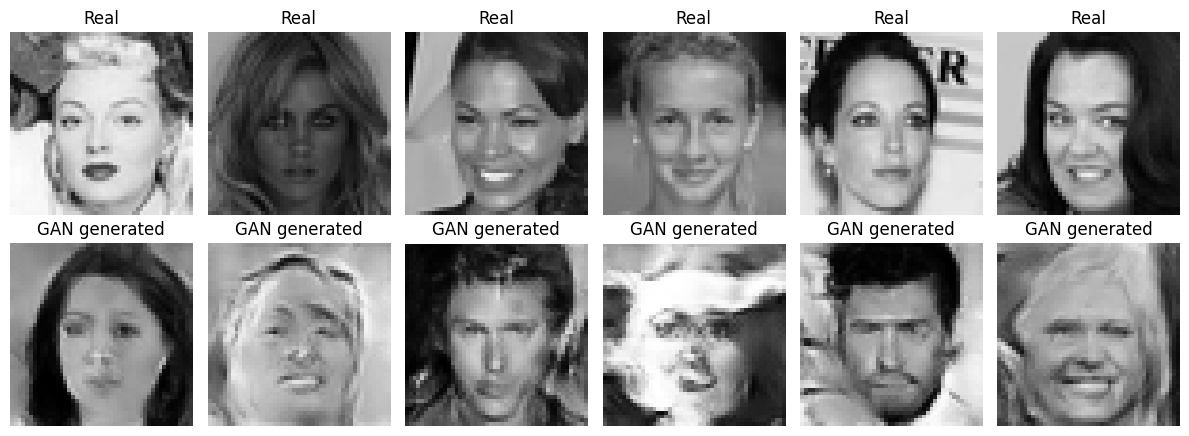

In [11]:
#Generate Faces
gan_faces = generate_faces(12).cpu().numpy()
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for i in range(6):
    axes[0][i].imshow(orig_np[i].reshape(48, 48), cmap="gray", vmin=0, vmax=1); axes[0][i].set_title("Real")
    axes[1][i].imshow(gan_faces[i].reshape(48, 48), cmap="gray", vmin=0, vmax=1); axes[1][i].set_title("GAN generated")
    axes[0][i].axis("off"); axes[1][i].axis("off")
plt.tight_layout(); plt.show()

In [12]:
#Build(Diffusion)
T = 500
betas = torch.linspace(1e-4 * 1000 / T, 0.02 * 1000 / T, T, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)
sqrt_ab = alpha_bar.sqrt()
sqrt_one_minus_ab = (1 - alpha_bar).sqrt()
ab_prev = torch.cat([torch.ones(1, device=device), alpha_bar[:-1]])
post_std = (betas * (1 - ab_prev) / (1 - alpha_bar)).sqrt()
post_coef1 = ab_prev.sqrt() * betas / (1 - alpha_bar)
post_coef2 = alphas.sqrt() * (1 - ab_prev) / (1 - alpha_bar)

def q_sample(x0, t, noise):
    return sqrt_ab[t][:, None, None, None] * x0 + sqrt_one_minus_ab[t][:, None, None, None] * noise

class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))
        args = t[:, None].float() * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch); self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch); self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(F.silu(t_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class AttnBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch); self.attn = nn.MultiheadAttention(ch, 4, batch_first=True)
    def forward(self, x):
        b, c, h, w = x.shape
        y = self.norm(x).reshape(b, c, h * w).transpose(1, 2)
        y, _ = self.attn(y, y, y, need_weights=False)
        return x + y.transpose(1, 2).reshape(b, c, h, w)

class UNet(nn.Module):
    def __init__(self, ch=64, t_dim=256):
        super().__init__()
        self.t_mlp = nn.Sequential(SinusoidalEmbedding(ch), nn.Linear(ch, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.in_conv = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, t_dim); self.pool1 = nn.Conv2d(ch, ch, 3, 2, 1)
        self.down2 = ResBlock(ch, ch * 2, t_dim); self.pool2 = nn.Conv2d(ch * 2, ch * 2, 3, 2, 1)
        self.down3 = ResBlock(ch * 2, ch * 2, t_dim)
        self.mid1 = ResBlock(ch * 2, ch * 2, t_dim); self.mid_attn = AttnBlock(ch * 2); self.mid2 = ResBlock(ch * 2, ch * 2, t_dim)
        self.up3 = ResBlock(ch * 4, ch * 2, t_dim); self.upsample2 = nn.ConvTranspose2d(ch * 2, ch * 2, 4, 2, 1)
        self.up2 = ResBlock(ch * 4, ch, t_dim); self.upsample1 = nn.ConvTranspose2d(ch, ch, 4, 2, 1)
        self.up1 = ResBlock(ch * 2, ch, t_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, 1, 3, padding=1))
    def forward(self, x, t):
        t_emb = self.t_mlp(t)
        d1 = self.down1(self.in_conv(x), t_emb)
        d2 = self.down2(self.pool1(d1), t_emb)
        d3 = self.down3(self.pool2(d2), t_emb)
        m = self.mid2(self.mid_attn(self.mid1(d3, t_emb)), t_emb)
        u3 = self.up3(torch.cat([m, d3], 1), t_emb)
        u2 = self.up2(torch.cat([self.upsample2(u3), d2], 1), t_emb)
        u1 = self.up1(torch.cat([self.upsample1(u2), d1], 1), t_emb)
        return self.out(u1)

unet = UNet().to(device)
ema_net = copy.deepcopy(unet).eval()
for p in ema_net.parameters():
    p.requires_grad_(False)

@torch.no_grad()
def update_ema(step):
    decay = min(0.999, (1 + step) / (10 + step))
    for pe, p in zip(ema_net.parameters(), unet.parameters()):
        pe.mul_(decay).add_(p.detach(), alpha=1 - decay)

@torch.no_grad()
def diffusion_sample(net, x_t, t_start, record=None, record_at=()):
    x = x_t
    for t in range(t_start, -1, -1):
        if record is not None and t in record_at:
            record[t] = x.clone()
        t_batch = torch.full((x.size(0),), t, device=device, dtype=torch.long)
        eps = net(x, t_batch)
        x0_hat = ((x - sqrt_one_minus_ab[t] * eps) / sqrt_ab[t]).clamp(-1, 1)
        x = post_coef1[t] * x0_hat + post_coef2[t] * x
        if t > 0:
            x = x + post_std[t] * torch.randn_like(x)
    return x

def generate_diffusion(n, bs=250):
    outs = []
    for i in range(0, n, bs):
        m = min(bs, n - i)
        x = diffusion_sample(ema_net, torch.randn(m, 1, 48, 48, device=device), T - 1)
        outs.append(((x + 1) / 2).clamp(0, 1).view(m, -1))
    return torch.cat(outs)

print("U-Net params:", sum(p.numel() for p in unet.parameters()))

U-Net params: 2864769


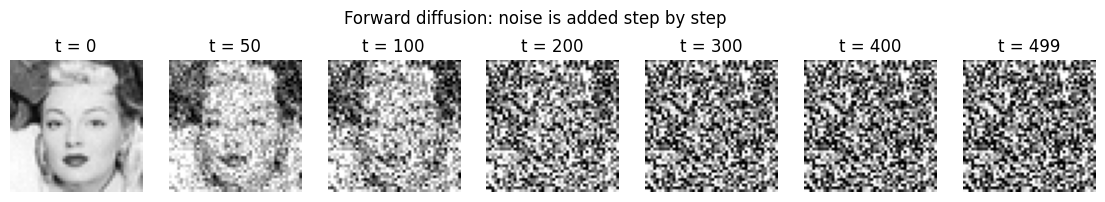

In [13]:
#forward process Chart
face = X_val_img[0:1].view(1, 1, 48, 48) * 2 - 1
noise_demo = torch.randn_like(face)
shown_t = [0, 50, 100, 200, 300, 400, T - 1]
fig, axes = plt.subplots(1, len(shown_t), figsize=(14, 2.4))
for ax, t in zip(axes, shown_t):
    xt = q_sample(face, torch.tensor([t], device=device), noise_demo)
    ax.imshow(((xt + 1) / 2).clamp(0, 1).cpu().numpy().reshape(48, 48), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {t}"); ax.axis("off")
plt.suptitle("Forward diffusion: noise is added step by step"); plt.show()

In [14]:
#train and save
DIFF_EPOCHS = 60
diff_loader = DataLoader(X_train_img, batch_size=128, shuffle=True, drop_last=True)
diff_opt = optim.Adam(unet.parameters(), lr=2e-4)
diff_sched = optim.lr_scheduler.CosineAnnealingLR(diff_opt, T_max=DIFF_EPOCHS * len(diff_loader), eta_min=1e-5)

fixed_diff_noise = torch.randn(8, 1, 48, 48, device=device)
diff_snapshot_epochs = [10, 30, DIFF_EPOCHS]
diff_snapshots = {}
diff_losses, diff_val_losses = [], []
step = 0

for epoch in range(1, DIFF_EPOCHS + 1):
    unet.train()
    total = 0
    for batch in diff_loader:
        b = batch.size(0)
        x0 = batch.view(b, 1, 48, 48) * 2 - 1
        flip = torch.rand(b, device=device) < 0.5
        x0 = torch.where(flip[:, None, None, None], x0.flip(3), x0)
        t = torch.randint(0, T, (b,), device=device)
        noise = torch.randn_like(x0)
        loss = F.mse_loss(unet(q_sample(x0, t, noise), t), noise)
        diff_opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
        diff_opt.step(); diff_sched.step(); update_ema(step)
        step += 1; total += loss.item()
    diff_losses.append(total / len(diff_loader))

    unet.eval()
    with torch.no_grad():
        v_total = 0
        for i in range(0, len(X_val_img), 250):
            xv = X_val_img[i:i + 250].view(-1, 1, 48, 48) * 2 - 1
            tv = torch.randint(0, T, (xv.size(0),), device=device)
            nv = torch.randn_like(xv)
            v_total += F.mse_loss(unet(q_sample(xv, tv, nv), tv), nv, reduction="sum").item()
        diff_val_losses.append(v_total / X_val_img.numel())

    if epoch in diff_snapshot_epochs:
        out = diffusion_sample(ema_net, fixed_diff_noise, T - 1)
        diff_snapshots[epoch] = ((out + 1) / 2).clamp(0, 1).cpu().numpy().reshape(-1, 48, 48)
    if epoch % 10 == 0 or epoch == 1:
        print("Epoch", epoch, "Train:", round(diff_losses[-1], 5), "Val:", round(diff_val_losses[-1], 5))

torch.save(ema_net.state_dict(), f"{D}/diffusion_unet_ema.pt")
print("Diffusion saved.")

Epoch 1 Train: 0.10097 Val: 0.05781
Epoch 10 Train: 0.0417 Val: 0.04108
Epoch 20 Train: 0.03927 Val: 0.0419
Epoch 30 Train: 0.03757 Val: 0.03893
Epoch 40 Train: 0.03925 Val: 0.03894
Epoch 50 Train: 0.03737 Val: 0.03704
Epoch 60 Train: 0.037 Val: 0.04064
Diffusion saved.


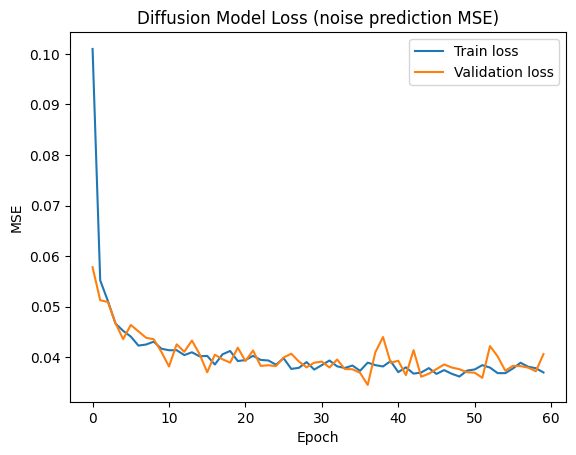

In [16]:
#Charts
plt.plot(diff_losses, label="Train loss"); plt.plot(diff_val_losses, label="Validation loss")
plt.title("Diffusion Model Loss (noise prediction MSE)"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

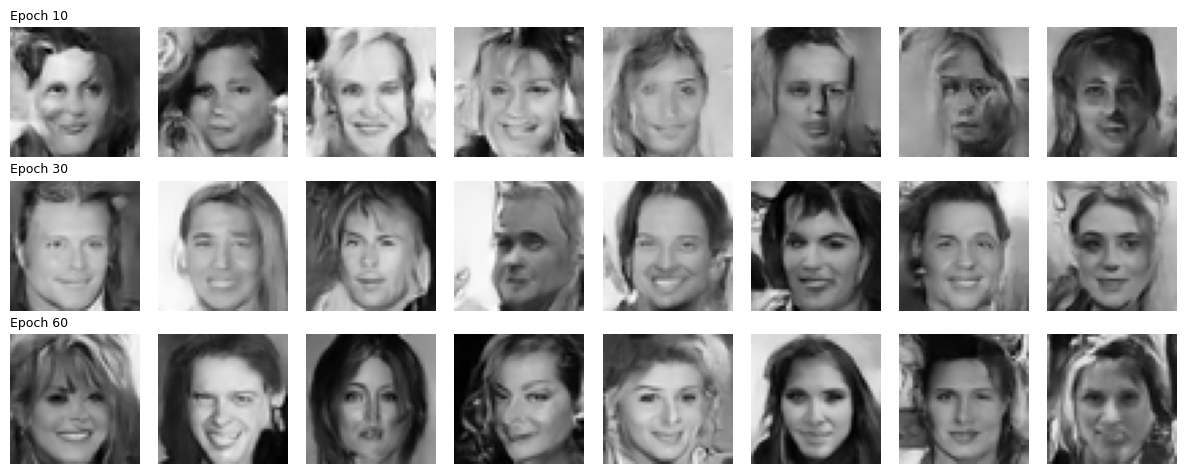

In [17]:
fig, axes = plt.subplots(len(diff_snapshots), 8, figsize=(12, 1.6 * len(diff_snapshots)))
for r, ep in enumerate(sorted(diff_snapshots)):
    for c in range(8):
        axes[r][c].imshow(diff_snapshots[ep][c], cmap="gray", vmin=0, vmax=1); axes[r][c].axis("off")
    axes[r][0].set_title(f"Epoch {ep}", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

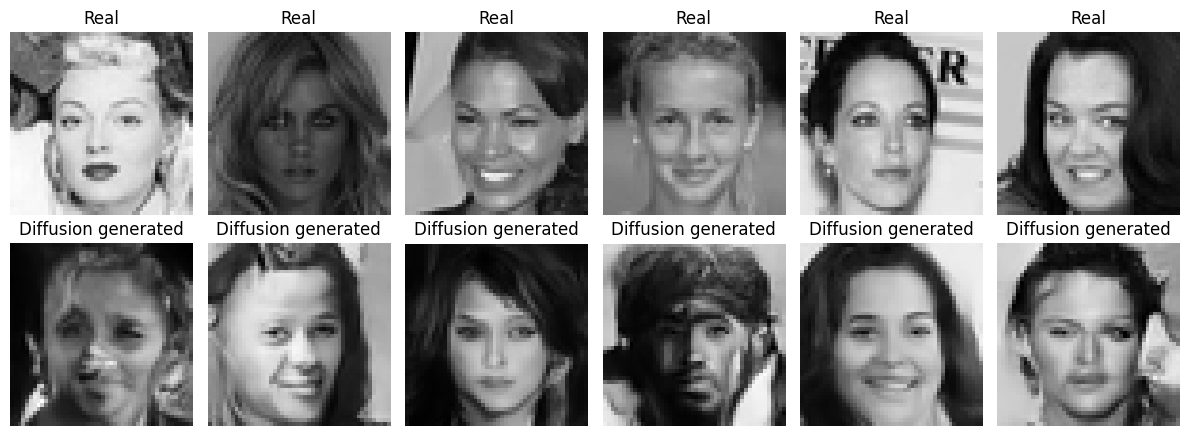

In [18]:
diff_faces = generate_diffusion(12).cpu().numpy()
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for i in range(6):
    axes[0][i].imshow(orig_np[i].reshape(48, 48), cmap="gray", vmin=0, vmax=1); axes[0][i].set_title("Real")
    axes[1][i].imshow(diff_faces[i].reshape(48, 48), cmap="gray", vmin=0, vmax=1); axes[1][i].set_title("Diffusion generated")
    axes[0][i].axis("off"); axes[1][i].axis("off")
plt.tight_layout(); plt.show()

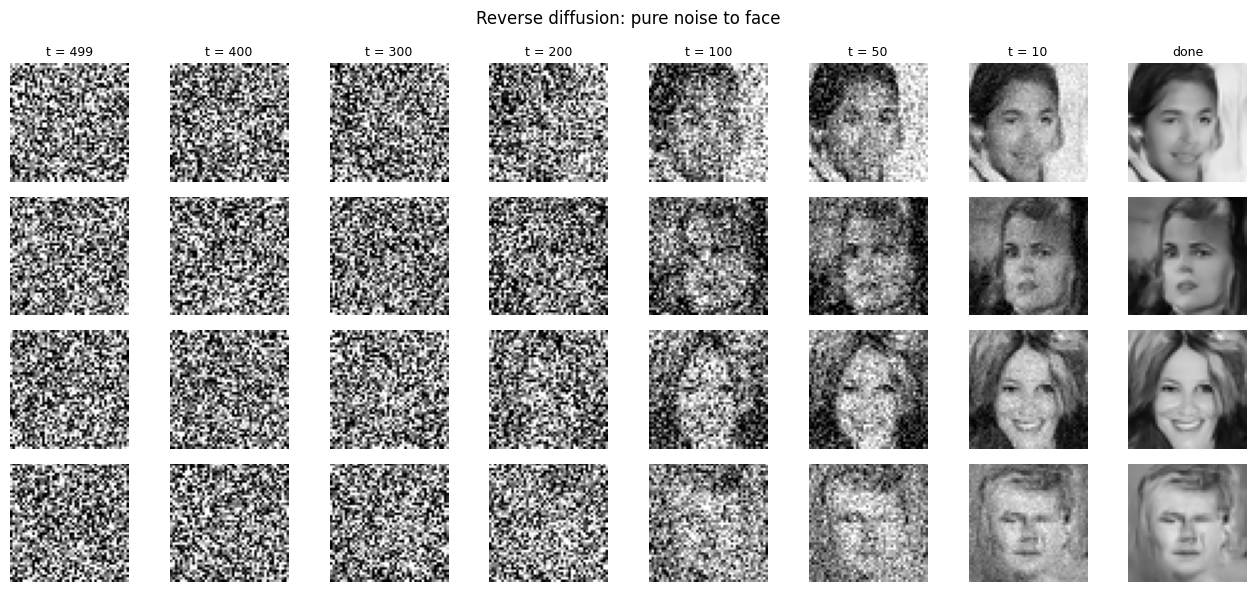

In [19]:
record_at = (T - 1, 400, 300, 200, 100, 50, 10)
record = {}
final = diffusion_sample(ema_net, torch.randn(4, 1, 48, 48, device=device), T - 1, record=record, record_at=record_at)
cols = list(record_at) + ["final"]
fig, axes = plt.subplots(4, len(cols), figsize=(13, 6))
for r in range(4):
    for c, key in enumerate(cols):
        img = final[r] if key == "final" else record[key][r]
        axes[r][c].imshow(((img + 1) / 2).clamp(0, 1).cpu().numpy().reshape(48, 48), cmap="gray", vmin=0, vmax=1)
        axes[r][c].axis("off")
        if r == 0:
            axes[r][c].set_title("done" if key == "final" else f"t = {key}", fontsize=9)
plt.suptitle("Reverse diffusion: pure noise to face"); plt.tight_layout(); plt.show()

In [20]:
#FID, Inception Score and CLIP for all four generators
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore
from torchmetrics.multimodal.clip_score import CLIPScore

N_EVAL = 1000

def to_rgb(x):
    return x.view(-1, 1, 48, 48).repeat(1, 3, 1, 1).clamp(0, 1)

def compute_fid_is(real_flat, fake_flat, bs=100):
    fid_metric = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    is_metric = InceptionScore(normalize=True).to(device)
    with torch.no_grad():
        for i in range(0, len(real_flat), bs):
            fid_metric.update(to_rgb(real_flat[i:i + bs]).to(device), real=True)
        for i in range(0, len(fake_flat), bs):
            batch = to_rgb(fake_flat[i:i + bs]).to(device)
            fid_metric.update(batch, real=False)
            is_metric.update(batch)
        is_mean, is_std = is_metric.compute()
    return fid_metric.compute().item(), is_mean.item(), is_std.item()

clip_prompt = "a photo of a human face"
clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch16").to(device)

def compute_clip_score(samples_flat, bs=100):
    clip_metric.reset()
    with torch.no_grad():
        for i in range(0, len(samples_flat), bs):
            imgs = to_rgb(samples_flat[i:i + bs]).mul(255).round().to(torch.uint8).to(device)
            clip_metric.update(imgs, [clip_prompt] * imgs.size(0))
    return clip_metric.compute().item()

torch.manual_seed(42)
real_set = X_train_img[:N_EVAL]

gan_samples = generate_faces(N_EVAL)
with torch.no_grad():
    vae_samples = img_vae.decoder(torch.randn(N_EVAL, 32, device=device))
    codes = img_ae.encoder(X_train_img)
    mu_c, sd_c = codes.mean(0), codes.std(0)        # the AE has no prior, so sample from a Gaussian fitted to its codes
    ae_samples = img_ae.decoder(mu_c + sd_c * torch.randn(N_EVAL, LAT_AE, device=device))
diff_samples = generate_diffusion(N_EVAL)

gan_fid, gan_is, gan_is_std = compute_fid_is(real_set, gan_samples)
vae_fid, vae_is, vae_is_std = compute_fid_is(real_set, vae_samples)
ae_fid, ae_is, ae_is_std = compute_fid_is(real_set, ae_samples)
diff_fid, diff_is, diff_is_std = compute_fid_is(real_set, diff_samples)
real_fid, real_is, real_is_std = compute_fid_is(real_set, X_val_img[:N_EVAL])

gan_clip = compute_clip_score(gan_samples); vae_clip = compute_clip_score(vae_samples)
ae_clip = compute_clip_score(ae_samples); diff_clip = compute_clip_score(diff_samples)
real_clip = compute_clip_score(X_val_img[:N_EVAL])

for n, f_, i_, c_ in [("AE", ae_fid, ae_is, ae_clip), ("VAE", vae_fid, vae_is, vae_clip),
                      ("GAN", gan_fid, gan_is, gan_clip), ("Diffusion", diff_fid, diff_is, diff_clip),
                      ("Real held-out", real_fid, real_is, real_clip)]:
    print(f"{n:14s} FID: {f_:.2f} | IS: {i_:.3f} | CLIP: {c_:.2f}")
print("Lower FID is better. Higher IS and CLIP are better.")

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 163MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'

In [21]:

# FID, INCEPTION SCORE AND CLIP EVALUATION
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd

from PIL import Image
from transformers import CLIPModel, CLIPProcessor

from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore

# 1. DEVICE

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

# 2. SETTINGS


N_EVAL = 1000
BATCH_SIZE = 100
CLIP_BATCH_SIZE = 32

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 3. CONVERT GRAYSCALE 48x48 IMAGES TO RGB

def to_rgb(x):

    x = x.reshape(-1, 1, 48, 48)

    # Convert grayscale to RGB
    x = x.repeat(1, 3, 1, 1)

    # Convert values to [0, 1]
    x = x.float().clamp(0, 1)

    return x


# 4. FID AND INCEPTION SCORE

def compute_fid_is(real_flat, fake_flat, bs=BATCH_SIZE):

    fid_metric = FrechetInceptionDistance(
        feature=2048,
        normalize=True
    ).to(device)

    is_metric = InceptionScore(
        normalize=True
    ).to(device)

    # Add real images to FID
    with torch.no_grad():

        for i in range(0, len(real_flat), bs):

            real_batch = to_rgb(
                real_flat[i:i + bs]
            ).to(device)

            fid_metric.update(
                real_batch,
                real=True
            )

        # Add generated images
        for i in range(0, len(fake_flat), bs):

            fake_batch = to_rgb(
                fake_flat[i:i + bs]
            ).to(device)

            fid_metric.update(
                fake_batch,
                real=False
            )

            is_metric.update(fake_batch)

        # Calculate Inception Score
        is_mean, is_std = is_metric.compute()

        # Calculate FID
        fid_value = fid_metric.compute()

    return (
        fid_value.item(),
        is_mean.item(),
        is_std.item()
    )


# 5. LOAD CLIP MODEL


print("\nLoading CLIP model...")

clip_model_name = "openai/clip-vit-base-patch16"

clip_model = CLIPModel.from_pretrained(
    clip_model_name
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    clip_model_name
)

clip_model.eval()

clip_prompt = "a photo of a human face"

print("CLIP loaded successfully!")


# 6. CLIP SCORE FUNCTION

def compute_clip_score(samples_flat, bs=CLIP_BATCH_SIZE):

    all_scores = []

    with torch.no_grad():

        for i in range(0, len(samples_flat), bs):

            # Convert images to RGB
            batch = to_rgb(
                samples_flat[i:i + bs]
            )

            batch = batch.detach().cpu().float().clamp(0, 1)

            pil_images = []

            for img in batch:

                img_array = (
                    img.permute(1, 2, 0).numpy() * 255
                ).round().astype(np.uint8)

                pil_images.append(
                    Image.fromarray(img_array)
                )

            # Prepare CLIP inputs
            inputs = clip_processor(
                images=pil_images,
                text=[clip_prompt] * len(pil_images),
                return_tensors="pt",
                padding=True
            )

            inputs = {
                key: value.to(device)
                for key, value in inputs.items()
            }

            # Extract image features
            image_output = clip_model.vision_model(
                pixel_values=inputs["pixel_values"]
            )

            image_features = clip_model.visual_projection(
                image_output.pooler_output
            )

            # Extract text features
            text_output = clip_model.text_model(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"]
            )

            text_features = clip_model.text_projection(
                text_output.pooler_output
            )

            # Normalize features
            image_features = F.normalize(
                image_features,
                dim=-1
            )

            text_features = F.normalize(
                text_features,
                dim=-1
            )

            # Cosine similarity
            similarity = (
                image_features * text_features
            ).sum(dim=-1)

            # CLIPScore-style scaling
            scores = (
                similarity * 100
            ).clamp(min=0)

            all_scores.extend(
                scores.cpu().tolist()
            )

    return float(np.mean(all_scores))


# 7. PREPARE REAL DATA

print("\nPreparing real images...")

real_set = X_train_img[:N_EVAL]

print("Real images:", real_set.shape)


# 8. GENERATE GAN SAMPLES

print("\nGenerating GAN images...")

gan_samples = generate_faces(N_EVAL)

print("GAN images:", gan_samples.shape)


# 9. GENERATE VAE SAMPLES

print("\nGenerating VAE images...")

with torch.no_grad():

    vae_samples = img_vae.decoder(
        torch.randn(
            N_EVAL,
            32,
            device=device
        )
    )

print("VAE images:", vae_samples.shape)


# 10. GENERATE AE SAMPLES

print("\nGenerating AE images...")

with torch.no_grad():

    codes = img_ae.encoder(X_train_img)

    mu_c = codes.mean(0)

    sd_c = codes.std(0)

    ae_samples = img_ae.decoder(
        mu_c + sd_c * torch.randn(
            N_EVAL,
            LAT_AE,
            device=device
        )
    )

print("AE images:", ae_samples.shape)


# 11. GENERATE DIFFUSION SAMPLES

print("\nGenerating Diffusion images...")

diff_samples = generate_diffusion(N_EVAL)

print("Diffusion images:", diff_samples.shape)


# 12. CALCULATE FID AND INCEPTION SCORE

print("\nCalculating FID and Inception Score...")

gan_fid, gan_is, gan_is_std = compute_fid_is(
    real_set, gan_samples
)

vae_fid, vae_is, vae_is_std = compute_fid_is(
    real_set, vae_samples
)

ae_fid, ae_is, ae_is_std = compute_fid_is(
    real_set, ae_samples
)

diff_fid, diff_is, diff_is_std = compute_fid_is(
    real_set, diff_samples
)

# Real held-out reference
real_fid, real_is, real_is_std = compute_fid_is(
    real_set, X_val_img[:N_EVAL]
)


# 13. CALCULATE CLIP SIMILARITY

print("\nCalculating CLIP similarity...")

gan_clip = compute_clip_score(gan_samples)

vae_clip = compute_clip_score(vae_samples)

ae_clip = compute_clip_score(ae_samples)

diff_clip = compute_clip_score(diff_samples)

real_clip = compute_clip_score(
    X_val_img[:N_EVAL]
)


# 14. DISPLAY FINAL RESULTS

results = {

    "Model": [
        "AE",
        "VAE",
        "GAN",
        "Diffusion",
        "Real held-out"
    ],

    "FID": [
        ae_fid,
        vae_fid,
        gan_fid,
        diff_fid,
        real_fid
    ],

    "Inception Score": [
        ae_is,
        vae_is,
        gan_is,
        diff_is,
        real_is
    ],

    "IS Std": [
        ae_is_std,
        vae_is_std,
        gan_is_std,
        diff_is_std,
        real_is_std
    ],

    "CLIP Similarity": [
        ae_clip,
        vae_clip,
        gan_clip,
        diff_clip,
        real_clip
    ]
}

comparison_df = pd.DataFrame(results)

print("\n")
print("=" * 75)
print("       COGNITIVE MIRROR - GENERATIVE MODEL EVALUATION")
print("=" * 75)

display(
    comparison_df.round(4)
)

print("\nEvaluation completed!")

print("Lower FID is generally better.")
print("Higher Inception Score is generally better.")
print("Higher CLIP similarity indicates stronger image-text alignment.")


Using device: cuda

Loading CLIP model...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded successfully!

Preparing real images...
Real images: torch.Size([1000, 2304])

Generating GAN images...
GAN images: torch.Size([1000, 2304])

Generating VAE images...
VAE images: torch.Size([1000, 2304])

Generating AE images...
AE images: torch.Size([1000, 2304])

Generating Diffusion images...
Diffusion images: torch.Size([1000, 2304])

Calculating FID and Inception Score...


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)



Calculating CLIP similarity...


       COGNITIVE MIRROR - GENERATIVE MODEL EVALUATION


,Model,FID,Inception Score,IS Std,CLIP Similarity
0,AE,158.9164,1.7500,0.0604,25.3863
1,VAE,125.6494,2.0567,0.1437,26.8395
2,GAN,47.4832,1.8635,0.0853,23.3276
3,Diffusion,33.0815,1.8190,0.0688,23.2012
4,Real held-out,18.2298,2.4523,0.2025,21.8788



Evaluation completed!
Lower FID is generally better.
Higher Inception Score is generally better.
Higher CLIP similarity indicates stronger image-text alignment.


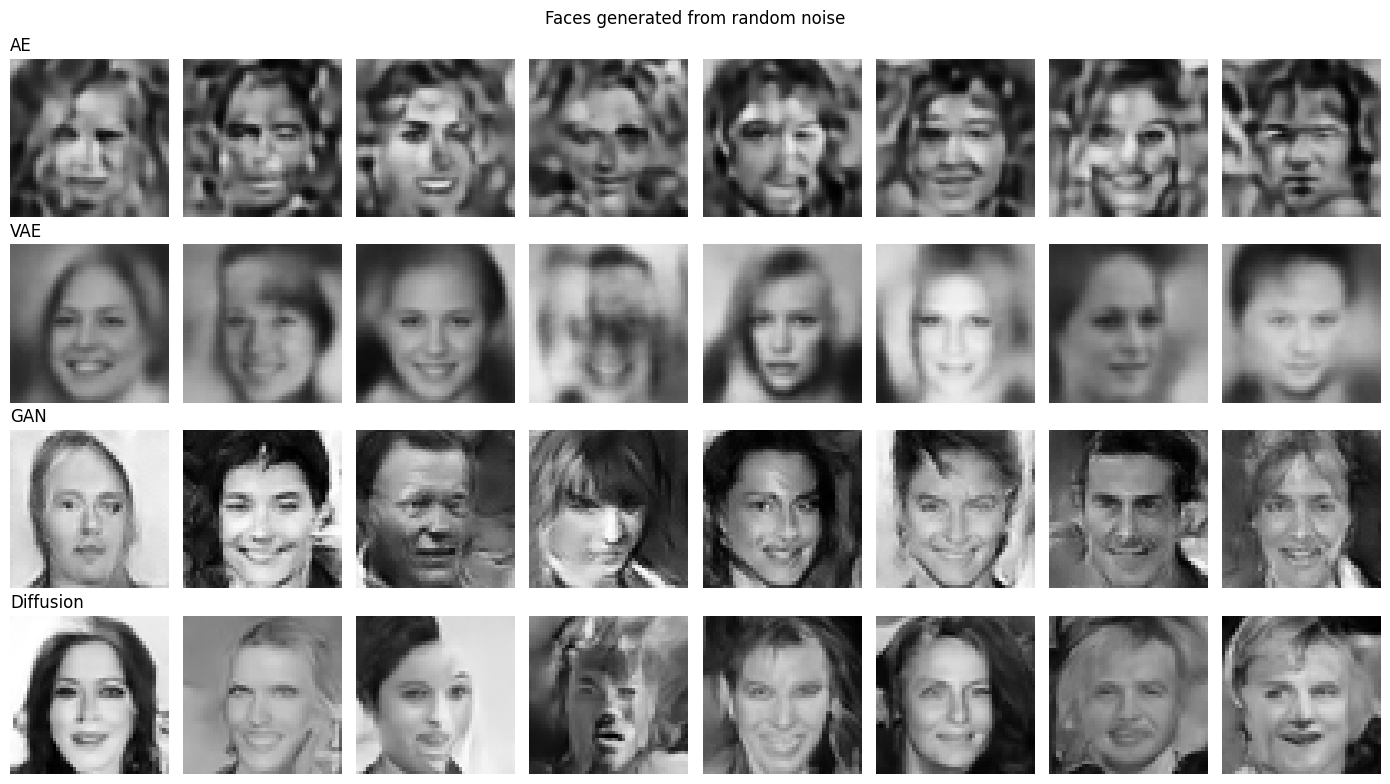

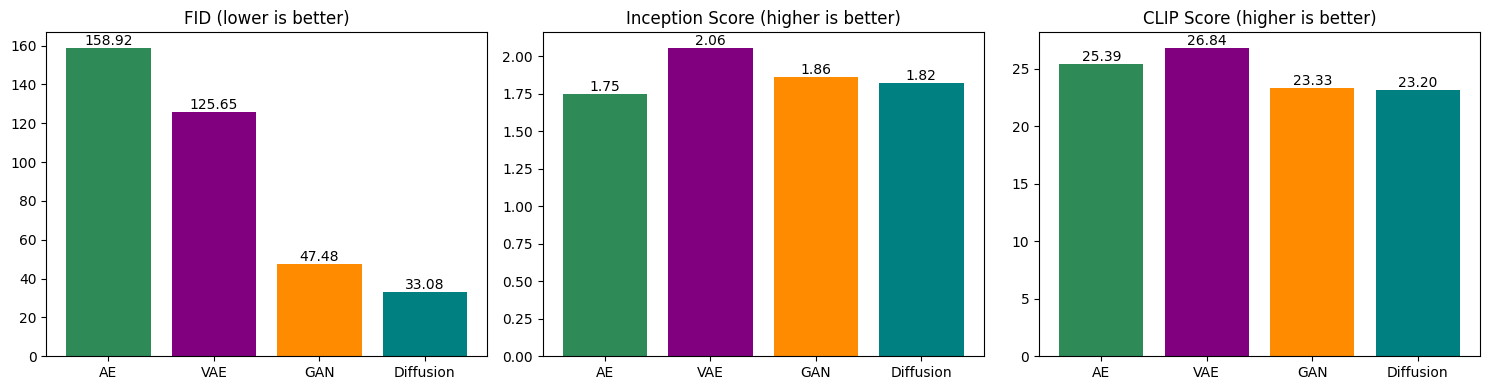

Inception was trained on photos, so on 48x48 grayscale faces use FID and IS to rank models against each other, not as absolute scores.


In [22]:
#faces and bar charts, AE vs VAE vs GAN vs Diffusion
names = ["AE", "VAE", "GAN", "Diffusion"]
data = [ae_samples, vae_samples, gan_samples, diff_samples]
fig, axes = plt.subplots(4, 8, figsize=(14, 8))
for r in range(4):
    for c in range(8):
        axes[r][c].imshow(data[r][c].cpu().numpy().reshape(48, 48), cmap="gray", vmin=0, vmax=1); axes[r][c].axis("off")
    axes[r][0].set_title(names[r], loc="left")
plt.suptitle("Faces generated from random noise"); plt.tight_layout(); plt.show()

colors = ["seagreen", "purple", "darkorange", "teal"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(names, [ae_fid, vae_fid, gan_fid, diff_fid], color=colors); axes[0].set_title("FID (lower is better)")
axes[1].bar(names, [ae_is, vae_is, gan_is, diff_is], color=colors); axes[1].set_title("Inception Score (higher is better)")
axes[2].bar(names, [ae_clip, vae_clip, gan_clip, diff_clip], color=colors); axes[2].set_title("CLIP Score (higher is better)")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=10)
plt.tight_layout(); plt.show()
print("Inception was trained on photos, so on 48x48 grayscale faces use FID and IS to rank models against each other, not as absolute scores.")

Denoising SSIM at t=100: noisy 0.238 | AE 0.472 | VAE 0.561 | Diffusion 0.629


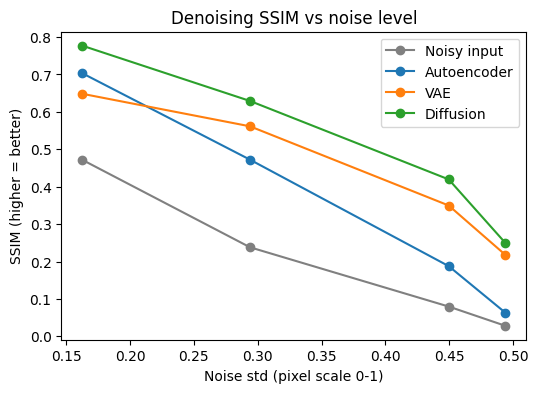

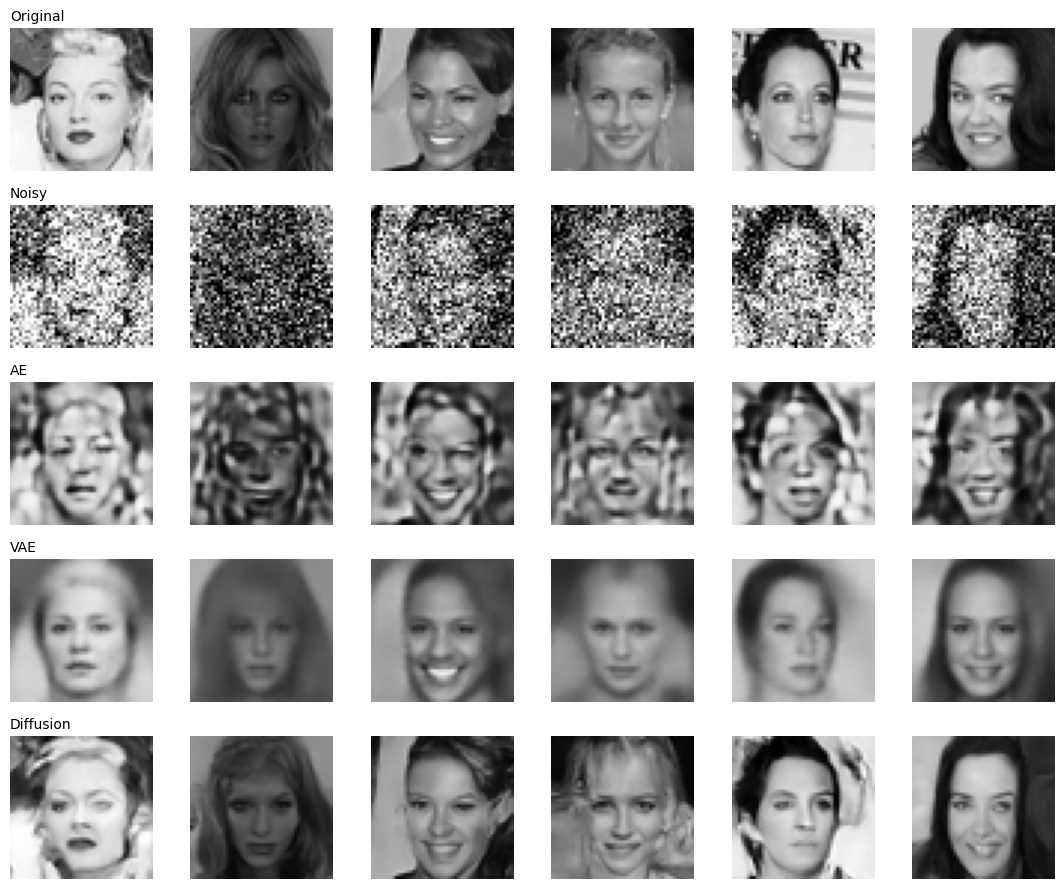

In [23]:
#denoising comparison, AE vs VAE vs Diffusion
def mean_ssim(a, b):
    a = a.detach().cpu().numpy().reshape(-1, 48, 48); b = b.detach().cpu().numpy().reshape(-1, 48, 48)
    return float(np.mean([ssim(a[i], b[i], data_range=1.0) for i in range(len(a))]))

torch.manual_seed(42)
N_SSIM = 200
clean01 = X_val_img[:N_SSIM]
clean_m11 = clean01.view(-1, 1, 48, 48) * 2 - 1
t_levels = [50, 100, 200, 300]
main_t0 = 100
noise_std, ssim_noisy, ssim_ae, ssim_vae, ssim_diff = [], [], [], [], []

for t0 in t_levels:
    noise = torch.randn_like(clean_m11)
    xt = q_sample(clean_m11, torch.full((N_SSIM,), t0, device=device, dtype=torch.long), noise)
    noisy01 = ((xt + 1) / 2).clamp(0, 1).view(N_SSIM, -1)
    with torch.no_grad():
        ae_out = img_ae(noisy01)
        vae_out_n = img_vae(noisy01)[0]
    diff_out = ((diffusion_sample(ema_net, xt, t0) + 1) / 2).clamp(0, 1).view(N_SSIM, -1)
    noise_std.append(float(sqrt_one_minus_ab[t0]) / 2)
    ssim_noisy.append(mean_ssim(clean01, noisy01)); ssim_ae.append(mean_ssim(clean01, ae_out))
    ssim_vae.append(mean_ssim(clean01, vae_out_n)); ssim_diff.append(mean_ssim(clean01, diff_out))
    if t0 == main_t0:
        demo = (noisy01, ae_out, vae_out_n, diff_out)

k = t_levels.index(main_t0)
diff_ssim, ae_den_ssim, vae_den_ssim = ssim_diff[k], ssim_ae[k], ssim_vae[k]
print(f"Denoising SSIM at t={main_t0}: noisy {ssim_noisy[k]:.3f} | AE {ae_den_ssim:.3f} | VAE {vae_den_ssim:.3f} | Diffusion {diff_ssim:.3f}")

plt.figure(figsize=(6, 4))
plt.plot(noise_std, ssim_noisy, marker="o", color="gray", label="Noisy input")
plt.plot(noise_std, ssim_ae, marker="o", label="Autoencoder")
plt.plot(noise_std, ssim_vae, marker="o", label="VAE")
plt.plot(noise_std, ssim_diff, marker="o", label="Diffusion")
plt.xlabel("Noise std (pixel scale 0-1)"); plt.ylabel("SSIM (higher = better)")
plt.title("Denoising SSIM vs noise level"); plt.legend(); plt.show()

rows = [("Original", clean01), ("Noisy", demo[0]), ("AE", demo[1]), ("VAE", demo[2]), ("Diffusion", demo[3])]
fig, axes = plt.subplots(len(rows), 6, figsize=(11, 9))
for r, (name, dd) in enumerate(rows):
    for c in range(6):
        axes[r][c].imshow(dd[c].detach().cpu().numpy().reshape(48, 48), cmap="gray", vmin=0, vmax=1); axes[r][c].axis("off")
    axes[r][0].set_title(name, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

In [24]:
#final comparison table
m = metrics
comparison_table = pd.DataFrame({
    "Model": ["Transformer", "Autoencoder (AE)", "Variational Autoencoder (VAE)", "GAN", "Diffusion"],
    "Data": ["Text (GoEmotions)", "Faces (CelebA)", "Faces (CelebA)", "Faces (CelebA)", "Faces (CelebA)"],
    "Accuracy": [f"{m['accuracy']:.3f}", "-", "-", "-", "-"],
    "F1 Score": [f"{m['f1']:.3f}", "-", "-", "-", "-"],
    "Precision": [f"{m['precision']:.3f}", "-", "-", "-", "-"],
    "Recall": [f"{m['recall']:.3f}", "-", "-", "-", "-"],
    "MSE": ["-", f"{m['ae_mse']:.4f}", f"{m['vae_mse']:.4f}", "-", "-"],
    "PSNR (dB)": ["-", f"{m['ae_psnr']:.2f}", f"{m['vae_psnr']:.2f}", "-", "-"],
    "SSIM (reconstruction)": ["-", f"{m['ae_ssim']:.3f}", f"{m['vae_ssim']:.3f}", "-", "-"],
    "SSIM (denoising, t=100)": ["-", f"{ae_den_ssim:.3f}", f"{vae_den_ssim:.3f}", "-", f"{diff_ssim:.3f}"],
    "KL Divergence": ["-", "-", f"{m['vae_kl']:.4f}", "-", "-"],
    "FID": ["-", f"{ae_fid:.2f}", f"{vae_fid:.2f}", f"{gan_fid:.2f}", f"{diff_fid:.2f}"],
    "Inception Score": ["-", f"{ae_is:.3f}", f"{vae_is:.3f}", f"{gan_is:.3f}", f"{diff_is:.3f}"],
    "CLIP Score": ["-", f"{ae_clip:.2f}", f"{vae_clip:.2f}", f"{gan_clip:.2f}", f"{diff_clip:.2f}"],
    "Generates new data": ["No", "No (weak)", "Yes", "Yes", "Yes"]})
display(comparison_table)

metrics.update({
    "gan_fid": float(gan_fid), "gan_is": float(gan_is), "gan_clip": float(gan_clip),
    "vae_fid": float(vae_fid), "vae_is": float(vae_is), "vae_clip": float(vae_clip),
    "ae_fid": float(ae_fid), "ae_is": float(ae_is), "ae_clip": float(ae_clip),
    "diff_fid": float(diff_fid), "diff_is": float(diff_is), "diff_clip": float(diff_clip),
    "diff_ssim_denoise": float(diff_ssim), "ae_ssim_denoise": float(ae_den_ssim), "vae_ssim_denoise": float(vae_den_ssim)})
json.dump(metrics, open(f"{D}/metrics.json", "w"))
torch.save({"mean": mu_c.cpu(), "std": sd_c.cpu()}, f"{D}/ae_latent_stats.pt")
comparison_table.to_csv(f"{D}/comparison_table.csv", index=False)
print(sorted(os.listdir(D)))

,Model,Data,Accuracy,F1 Score,Precision,Recall,MSE,PSNR (dB),SSIM (reconstruction),"SSIM (denoising, t=100)",KL Divergence,FID,Inception Score,CLIP Score,Generates new data
0,Transformer,Text (GoEmotions),0.912,0.235,0.226,0.355,-,-,-,-,-,-,-,-,No
1,Autoencoder (AE),Faces (CelebA),-,-,-,-,0.0028,25.49,0.889,0.472,-,158.92,1.750,25.39,No (weak)
2,Variational Autoencoder (VAE),Faces (CelebA),-,-,-,-,0.0100,20.01,0.682,0.561,2.4823,125.65,2.057,26.84,Yes
3,GAN,Faces (CelebA),-,-,-,-,-,-,-,-,-,47.48,1.863,23.33,Yes
4,Diffusion,Faces (CelebA),-,-,-,-,-,-,-,0.629,-,33.08,1.819,23.20,Yes


['ae_latent_stats.pt', 'ae_model.pt', 'comparison_table.csv', 'data.npz', 'diffusion_unet_ema.pt', 'gan_discriminator.pt', 'gan_generator.pt', 'metrics.json', 'tokenizer_saved', 'transformer_model.pt', 'transformer_model_backup.pt', 'vae_model.pt']


In [26]:
# SAVE ALL MODELS

import os
import torch
import shutil
import json

D = "/content/drive/MyDrive/cognitive_mirror"
os.makedirs(D, exist_ok=True)

# 1. SAVE AUTOENCODER
torch.save(
    img_ae.state_dict(),
    f"{D}/ae_model.pt"
)

# 2. SAVE VARIATIONAL AUTOENCODER
torch.save(
    img_vae.state_dict(),
    f"{D}/vae_model.pt"
)

# 3. SAVE GAN GENERATOR
torch.save(
    generator.state_dict(),
    f"{D}/gan_generator.pt"
)

# 4. SAVE GAN DISCRIMINATOR
torch.save(
    discriminator.state_dict(),
    f"{D}/gan_discriminator.pt"
)

# 5. SAVE DIFFUSION EMA MODEL
torch.save(
    ema_net.state_dict(),
    f"{D}/diffusion_unet_ema.pt"
)

# 6. SAVE AE LATENT STATISTICS
torch.save(
    {
        "mean": mu_c.detach().cpu(),
        "std": sd_c.detach().cpu()
    },
    f"{D}/ae_latent_stats.pt"
)

# 7. SAVE METRICS
with open(f"{D}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# 8. SAVE COMPARISON TABLE
comparison_table.to_csv(
    f"{D}/comparison_table.csv",
    index=False
)

print("All requested model files saved!")

All requested model files saved!


In [27]:

import os

D = "/content/drive/MyDrive/cognitive_mirror"

required_files = [
    "transformer_model.pt",
    "tokenizer_saved",
    "ae_model.pt",
    "vae_model.pt",
    "gan_generator.pt",
    "gan_discriminator.pt",
    "diffusion_unet_ema.pt",
    "ae_latent_stats.pt",
    "metrics.json",
    "comparison_table.csv"
]

print("COGNITIVE MIRROR - FINAL FILE CHECK")
print("-" * 50)

for name in required_files:
    path = os.path.join(D, name)
    if os.path.exists(path):
        print("SAVED:", name)
    else:
        print("MISSING:", name)

print("-" * 50)
print("Total items:", len(os.listdir(D)))


COGNITIVE MIRROR - FINAL FILE CHECK
--------------------------------------------------
SAVED: transformer_model.pt
SAVED: tokenizer_saved
SAVED: ae_model.pt
SAVED: vae_model.pt
SAVED: gan_generator.pt
SAVED: gan_discriminator.pt
SAVED: diffusion_unet_ema.pt
SAVED: ae_latent_stats.pt
SAVED: metrics.json
SAVED: comparison_table.csv
--------------------------------------------------
Total items: 12


In [28]:
import os

D = "/content/drive/MyDrive/cognitive_mirror"

print("Files in Cognitive Mirror folder:\n")

for file in sorted(os.listdir(D)):
    print(file)

Files in Cognitive Mirror folder:

ae_latent_stats.pt
ae_model.pt
comparison_table.csv
data.npz
diffusion_unet_ema.pt
gan_discriminator.pt
gan_generator.pt
metrics.json
tokenizer_saved
transformer_model.pt
transformer_model_backup.pt
vae_model.pt


In [32]:

# ============================================================
# COGNITIVE MIRROR - LOAD SAVED MODELS
# ============================================================

!pip install -q gradio transformers opencv-python-headless

import os
import cv2
import json
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import gradio as gr

from PIL import Image
from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModelForSequenceClassification
)

# ---------------- DEVICE AND DRIVE ----------------

from google.colab import drive
drive.mount("/content/drive")

D = "/content/drive/MyDrive/cognitive_mirror"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

with open(f"{D}/metrics.json", "r") as f:
    metrics = json.load(f)

LAT_AE = metrics.get("lat_ae", 256)
LABEL_NAMES = metrics.get("label_names", [])

# ---------------- HELPER ----------------

def load_weights(path):
    try:
        return torch.load(path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=device)

def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in ["state_dict", "model_state_dict", "model"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                return checkpoint[key]
    return checkpoint

# ============================================================
# 1. AUTOENCODER
# ============================================================

class ImageAE(nn.Module):
    def __init__(self, latent=LAT_AE):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Unflatten(1, (1, 48, 48)),
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(256 * 3 * 3, latent)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent, 256 * 3 * 3),
            nn.ReLU(),
            nn.Unflatten(1, (256, 3, 3)),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1),
            nn.Sigmoid(),
            nn.Flatten()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


# ============================================================
# 2. VARIATIONAL AUTOENCODER
# ============================================================

class ImageVAE(nn.Module):
    def __init__(self, latent=32):
        super().__init__()

        self.hidden = nn.Sequential(
            nn.Unflatten(1, (1, 48, 48)),
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Flatten()
        )

        self.mean_layer = nn.Linear(256 * 3 * 3, latent)
        self.logvar_layer = nn.Linear(256 * 3 * 3, latent)

        self.decoder = nn.Sequential(
            nn.Linear(latent, 256 * 3 * 3),
            nn.ReLU(),
            nn.Unflatten(1, (256, 3, 3)),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1),
            nn.Sigmoid(),
            nn.Flatten()
        )

    def forward(self, x):
        h = self.hidden(x)
        mean = self.mean_layer(h)
        logvar = self.logvar_layer(h)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)
        return self.decoder(z), mean, logvar


# ============================================================
# 3. GAN
# ============================================================

latent_dim = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.ConvTranspose2d(100, 256, 3, 1, 0, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),

            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(True),

            nn.ConvTranspose2d(32, 1, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), 100, 1, 1))


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(32, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.LeakyReLU(0.2, True),

            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),

            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 1)
        )

    def forward(self, x):
        return self.net(x)


# ============================================================
# 4. DIFFUSION MODEL
# ============================================================

T = 500

betas = torch.linspace(
    1e-4 * 1000 / T,
    0.02 * 1000 / T,
    T,
    device=device
)

alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)
sqrt_ab = alpha_bar.sqrt()
sqrt_one_minus_ab = (1 - alpha_bar).sqrt()

ab_prev = torch.cat([torch.ones(1, device=device), alpha_bar[:-1]])

post_std = (betas * (1 - ab_prev) / (1 - alpha_bar)).sqrt()
post_coef1 = ab_prev.sqrt() * betas / (1 - alpha_bar)
post_coef2 = alphas.sqrt() * (1 - ab_prev) / (1 - alpha_bar)


class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) *
            torch.arange(half, device=t.device) / (half - 1)
        )
        args = t[:, None].float() * freqs[None, :]
        return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)

        self.t_proj = nn.Linear(t_dim, out_ch)

        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)

        self.skip = (
            nn.Conv2d(in_ch, out_ch, 1)
            if in_ch != out_ch else nn.Identity()
        )

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(F.silu(t_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class AttnBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.attn = nn.MultiheadAttention(ch, 4, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        y = self.norm(x).reshape(b, c, h * w).transpose(1, 2)
        y, _ = self.attn(y, y, y, need_weights=False)
        return x + y.transpose(1, 2).reshape(b, c, h, w)


class UNet(nn.Module):
    def __init__(self, ch=64, t_dim=256):
        super().__init__()

        self.t_mlp = nn.Sequential(
            SinusoidalEmbedding(ch),
            nn.Linear(ch, t_dim),
            nn.SiLU(),
            nn.Linear(t_dim, t_dim)
        )

        self.in_conv = nn.Conv2d(1, ch, 3, padding=1)

        self.down1 = ResBlock(ch, ch, t_dim)
        self.pool1 = nn.Conv2d(ch, ch, 3, 2, 1)

        self.down2 = ResBlock(ch, ch * 2, t_dim)
        self.pool2 = nn.Conv2d(ch * 2, ch * 2, 3, 2, 1)

        self.down3 = ResBlock(ch * 2, ch * 2, t_dim)

        self.mid1 = ResBlock(ch * 2, ch * 2, t_dim)
        self.mid_attn = AttnBlock(ch * 2)
        self.mid2 = ResBlock(ch * 2, ch * 2, t_dim)

        self.up3 = ResBlock(ch * 4, ch * 2, t_dim)
        self.upsample2 = nn.ConvTranspose2d(ch * 2, ch * 2, 4, 2, 1)

        self.up2 = ResBlock(ch * 4, ch, t_dim)
        self.upsample1 = nn.ConvTranspose2d(ch, ch, 4, 2, 1)

        self.up1 = ResBlock(ch * 2, ch, t_dim)

        self.out = nn.Sequential(
            nn.GroupNorm(8, ch),
            nn.SiLU(),
            nn.Conv2d(ch, 1, 3, padding=1)
        )

    def forward(self, x, t):
        t_emb = self.t_mlp(t)

        d1 = self.down1(self.in_conv(x), t_emb)
        d2 = self.down2(self.pool1(d1), t_emb)
        d3 = self.down3(self.pool2(d2), t_emb)

        m = self.mid2(
            self.mid_attn(self.mid1(d3, t_emb)),
            t_emb
        )

        u3 = self.up3(torch.cat([m, d3], 1), t_emb)
        u2 = self.up2(
            torch.cat([self.upsample2(u3), d2], 1), t_emb
        )
        u1 = self.up1(
            torch.cat([self.upsample1(u2), d1], 1), t_emb
        )

        return self.out(u1)


# ============================================================
# LOAD CHECKPOINTS
# ============================================================

img_ae = ImageAE().to(device)
img_ae.load_state_dict(load_weights(f"{D}/ae_model.pt"))
img_ae.eval()

img_vae = ImageVAE().to(device)
img_vae.load_state_dict(load_weights(f"{D}/vae_model.pt"))
img_vae.eval()

generator = Generator().to(device)
generator.load_state_dict(load_weights(f"{D}/gan_generator.pt"))
generator.eval()

ema_net = UNet().to(device)
ema_net.load_state_dict(load_weights(f"{D}/diffusion_unet_ema.pt"))
ema_net.eval()

latent_stats = load_weights(f"{D}/ae_latent_stats.pt")
ae_mean = latent_stats["mean"].to(device)
ae_std = latent_stats["std"].to(device)

print("\nAll four image-generation model types loaded successfully.")
print("AE, VAE, GAN and Diffusion are ready.")

# ============================================================
# LOAD TRANSFORMER IF CONFIGURATION IS AVAILABLE
# ============================================================

text_model = None
text_tokenizer = None
text_status = "Transformer not loaded."

try:
    tokenizer_path = f"{D}/tokenizer_saved"

    text_tokenizer = AutoTokenizer.from_pretrained(
        tokenizer_path,
        local_files_only=True
    )

    text_config = AutoConfig.from_pretrained(
        tokenizer_path,
        local_files_only=True
    )

    checkpoint = extract_state_dict(
        load_weights(f"{D}/transformer_model.pt")
    )

    text_model = AutoModelForSequenceClassification.from_config(
        text_config
    ).to(device)

    result = text_model.load_state_dict(checkpoint, strict=False)

    if len(result.missing_keys) > 0.5 * len(text_model.state_dict()):
        raise RuntimeError(
            "Checkpoint does not match the detected Transformer architecture."
        )

    text_model.eval()
    text_status = "Transformer loaded successfully."

except Exception as e:
    text_model = None
    text_status = (
        "Transformer needs its matching architecture/configuration. "
        + str(e)[:250]
    )

print("Transformer status:", text_status)

# ============================================================
# MODEL LOADING CHECK
# ============================================================

print("\nMODEL STATUS")
print("AE: READY")
print("VAE: READY")
print("GAN: READY")
print("Diffusion: READY")
print("Transformer:", text_status)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda

All four image-generation model types loaded successfully.
AE, VAE, GAN and Diffusion are ready.
Transformer status: Transformer needs its matching architecture/configuration. Unrecognized model in /content/drive/MyDrive/cognitive_mirror/tokenizer_saved. Should have a `model_type` key in its config.json.

MODEL STATUS
AE: READY
VAE: READY
GAN: READY
Diffusion: READY
Transformer: Transformer needs its matching architecture/configuration. Unrecognized model in /content/drive/MyDrive/cognitive_mirror/tokenizer_saved. Should have a `model_type` key in its config.json.


In [ ]:

# ============================================================
# COGNITIVE MIRROR - GRADIO GUI
# ============================================================

# ---------- IMAGE PREPROCESSING ----------

def prepare_face(image):
    if image is None:
        raise gr.Error("Please upload an image first.")

    image = image.convert("L").resize((48, 48))
    arr = np.asarray(image, dtype=np.float32) / 255.0

    tensor = torch.tensor(
        arr, dtype=torch.float32, device=device
    ).view(1, -1)

    return tensor


def tensor_to_pil(tensor):
    arr = tensor.detach().cpu().numpy().reshape(48, 48)
    arr = np.clip(arr * 255, 0, 255).astype(np.uint8)
    return Image.fromarray(arr, mode="L")


# ---------- AE RECONSTRUCTION ----------

@torch.no_grad()
def reconstruct_ae(image):
    x = prepare_face(image)
    reconstructed = img_ae(x)
    return tensor_to_pil(x), tensor_to_pil(reconstructed)


# ---------- VAE RECONSTRUCTION ----------

@torch.no_grad()
def reconstruct_vae(image):
    x = prepare_face(image)

    hidden = img_vae.hidden(x)
    mean = img_vae.mean_layer(hidden)

    reconstructed = img_vae.decoder(mean)

    return tensor_to_pil(x), tensor_to_pil(reconstructed)


# ---------- VAE GENERATION ----------

@torch.no_grad()
def generate_vae_gui(count):
    count = int(count)
    z = torch.randn(count, 32, device=device)

    generated = img_vae.decoder(z)

    return [tensor_to_pil(x) for x in generated]


# ---------- AE GENERATION ----------

@torch.no_grad()
def generate_ae_gui(count):
    count = int(count)

    z = ae_mean + ae_std * torch.randn(
        count, LAT_AE, device=device
    )

    generated = img_ae.decoder(z)

    return [tensor_to_pil(x) for x in generated]


# ---------- GAN GENERATION ----------

@torch.no_grad()
def generate_gan_gui(count):
    count = int(count)

    noise = torch.randn(count, 100, device=device)
    generated = generator(noise)

    generated = ((generated + 1) / 2).clamp(0, 1)

    return [
        tensor_to_pil(x)
        for x in generated.view(-1, 48, 48)
    ]


# ---------- DIFFUSION GENERATION ----------

@torch.no_grad()
def diffusion_sample_gui(count):
    count = int(count)

    x = torch.randn(
        count, 1, 48, 48, device=device
    )

    for t in range(T - 1, -1, -1):
        t_batch = torch.full(
            (count,), t, device=device, dtype=torch.long
        )

        eps = ema_net(x, t_batch)

        x0_hat = (
            (x - sqrt_one_minus_ab[t] * eps) / sqrt_ab[t]
        ).clamp(-1, 1)

        x = post_coef1[t] * x0_hat + post_coef2[t] * x

        if t > 0:
            x = x + post_std[t] * torch.randn_like(x)

    generated = ((x + 1) / 2).clamp(0, 1)

    return [
        tensor_to_pil(img)
        for img in generated
    ]


# ---------- TRANSFORMER TEXT EMOTION ----------

def analyze_text(text):
    if not text or not text.strip():
        raise gr.Error("Please enter some text.")

    if text_model is None or text_tokenizer is None:
        return (
            "Transformer is not loaded. Check the matching model "
            "architecture and configuration before using this feature."
        )

    inputs = text_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        logits = text_model(**inputs).logits[0]
        probabilities = torch.sigmoid(logits).cpu().numpy()

    labels = LABEL_NAMES

    if isinstance(labels, dict):
        labels = [
            labels.get(str(i), labels.get(i, f"Label {i}"))
            for i in range(len(probabilities))
        ]

    if not isinstance(labels, list) or len(labels) != len(probabilities):
        labels = [f"Emotion {i}" for i in range(len(probabilities))]

    ranked = sorted(
        zip(labels, probabilities),
        key=lambda x: x[1],
        reverse=True
    )

    output = "Estimated emotion scores:\n\n"

    for label, score in ranked[:5]:
        output += f"{label}: {score * 100:.2f}%\n"

    output += (
        "\nThese are model estimates from text, not a psychological "
        "diagnosis or a definitive measurement of someone's feelings."
    )

    return output


# ---------- VIDEO FACE DETECTION ----------

def analyze_video(video_path):
    if video_path is None:
        raise gr.Error("Please upload an MP4 video.")

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise gr.Error("Could not open the video.")

    face_detector = cv2.CascadeClassifier(
        cv2.data.haarcascades +
        "haarcascade_frontalface_default.xml"
    )

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0:
        fps = 25

    frame_interval = max(1, int(fps))
    frame_number = 0
    processed = 0
    total_faces = 0
    gallery = []

    while True:
        success, frame = cap.read()

        if not success:
            break

        if frame_number % frame_interval == 0:
            gray = cv2.cvtColor(
                frame, cv2.COLOR_BGR2GRAY
            )

            faces = face_detector.detectMultiScale(
                gray,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(30, 30)
            )

            for (x, y, w, h) in faces:
                cv2.rectangle(
                    frame,
                    (x, y),
                    (x + w, y + h),
                    (0, 255, 0),
                    2
                )

            total_faces += len(faces)
            processed += 1

            frame_rgb = cv2.cvtColor(
                frame, cv2.COLOR_BGR2RGB
            )

            gallery.append(Image.fromarray(frame_rgb))

            if len(gallery) >= 20:
                break

        frame_number += 1

    cap.release()

    if processed == 0:
        return [], "No frames could be processed."

    summary = (
        f"Frames analysed: {processed}\n"
        f"Faces detected across sampled frames: {total_faces}\n\n"
        "This version performs face detection only. It does not "
        "classify facial emotions because a verified FER2013 "
        "emotion-classification checkpoint has not yet been connected."
    )

    return gallery, summary


# ============================================================
# GRADIO DESIGN
# ============================================================

with gr.Blocks(
    title="Cognitive Mirror",
    theme=gr.themes.Soft()
) as demo:

    gr.Markdown("""
    # 🧠 Cognitive Mirror

    ### A Generative AI System for Human Behavior Understanding and Psychological Reflection

    Explore text emotion estimates, facial image reconstruction,
    generative face models and video face detection.

    **Note:** Outputs are experimental AI estimates, not medical
    or psychological diagnoses.
    """)

    # ---------------- TEXT ANALYSIS ----------------

    with gr.Tab("💬 Text Emotion Analysis"):

        gr.Markdown("### Transformer-based emotion analysis")

        text_input = gr.Textbox(
            label="Enter your text",
            placeholder="Example: I feel happy and excited today...",
            lines=4
        )

        text_button = gr.Button(
            "Analyze Text",
            variant="primary"
        )

        text_output = gr.Textbox(
            label="Emotion Analysis Results",
            lines=9
        )

        text_button.click(
            analyze_text,
            inputs=text_input,
            outputs=text_output
        )

        gr.Markdown(
            f"**Transformer status:** {text_status}"
        )

    # ---------------- IMAGE RECONSTRUCTION ----------------

    with gr.Tab("🖼️ Face Reconstruction"):

        gr.Markdown("""
        ### Upload a face image

        The image is converted to grayscale and resized to 48 × 48
        pixels to match your trained models.
        """)

        with gr.Row():

            with gr.Column():
                reconstruction_input = gr.Image(
                    label="Upload Face Image",
                    type="pil"
                )

                ae_button = gr.Button("Reconstruct with AE")
                vae_button = gr.Button("Reconstruct with VAE")

            with gr.Column():
                original_output = gr.Image(
                    label="Original Image",
                    type="pil"
                )

                reconstructed_output = gr.Image(
                    label="Reconstructed Image",
                    type="pil"
                )

        ae_button.click(
            reconstruct_ae,
            inputs=reconstruction_input,
            outputs=[original_output, reconstructed_output]
        )

        vae_button.click(
            reconstruct_vae,
            inputs=reconstruction_input,
            outputs=[original_output, reconstructed_output]
        )

    # ---------------- IMAGE GENERATION ----------------

    with gr.Tab("✨ Face Generation"):

        gr.Markdown("""
        ### Generate new synthetic faces

        Choose a model and the number of images to generate.
        Diffusion generation may take longer because it uses
        500 reverse-denoising steps.
        """)

        number_of_images = gr.Slider(
            minimum=1,
            maximum=8,
            value=4,
            step=1,
            label="Number of Images"
        )

        with gr.Row():
            ae_gen_button = gr.Button("Generate with AE")
            vae_gen_button = gr.Button("Generate with VAE")

        with gr.Row():
            gan_gen_button = gr.Button("Generate with GAN")
            diffusion_gen_button = gr.Button(
                "Generate with Diffusion",
                variant="primary"
            )

        generated_gallery = gr.Gallery(
            label="Generated Faces",
            columns=4,
            height="auto"
        )

        ae_gen_button.click(
            generate_ae_gui,
            inputs=number_of_images,
            outputs=generated_gallery
        )

        vae_gen_button.click(
            generate_vae_gui,
            inputs=number_of_images,
            outputs=generated_gallery
        )

        gan_gen_button.click(
            generate_gan_gui,
            inputs=number_of_images,
            outputs=generated_gallery
        )

        diffusion_gen_button.click(
            diffusion_sample_gui,
            inputs=number_of_images,
            outputs=generated_gallery
        )

    # ---------------- VIDEO ANALYSIS ----------------

    with gr.Tab("🎥 Video Analysis"):

        gr.Markdown("""
        ### Video face detection

        Upload an MP4 file. The system samples approximately one
        frame per second and detects visible faces.
        """)

        video_input = gr.Video(
            label="Upload MP4 Video",
            sources=["upload"]
        )

        video_button = gr.Button(
            "Analyze Video",
            variant="primary"
        )

        video_gallery = gr.Gallery(
            label="Processed Video Frames",
            columns=3,
            height="auto"
        )

        video_summary = gr.Textbox(
            label="Video Analysis Summary",
            lines=6
        )

        video_button.click(
            analyze_video,
            inputs=video_input,
            outputs=[video_gallery, video_summary]
        )

    # ---------------- MODEL INFORMATION ----------------

    with gr.Tab("📊 Model Information"):

        gr.Markdown("### Saved model information")

        gr.JSON({
            "Transformer": "Text emotion classification",
            "Autoencoder": "Face reconstruction and latent sampling",
            "Variational Autoencoder": "Face reconstruction and generation",
            "GAN": "Synthetic face generation",
            "Diffusion": "Iterative synthetic face generation",
            "Video": "OpenCV face detection; FER2013 not connected",
            "Device": str(device),
            "Image Size": "48 x 48 grayscale",
            "Evaluation Metrics": metrics
        })

    gr.Markdown("""
    ---
    **Cognitive Mirror | Generative AI Project**

    This application is intended for educational and reflective
    purposes. Generated faces are synthetic, and model predictions
    should not be treated as reliable evidence of a person's
    internal emotional state.
    """)


# ============================================================
# LAUNCH APPLICATION
# ============================================================

demo.queue().launch(
    share=True,
    debug=True
)


/tmp/ipykernel_358/3925687288.py:271: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://3fb588ce4e8bd93e04.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/tmp/ipykernel_358/3925687288.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L")
/tmp/ipykernel_358/3925687288.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L")
/tmp/ipykernel_358/3925687288.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L")
/tmp/ipykernel_358/3925687288.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L")
/tmp/ipykernel_358/3925687288.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, mode="L")
/tmp/ipykernel_358/3925687288.py:24: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-